In [10]:
import tabula
import pandas as pd
import os
import matplotlib.pyplot as plt

folder = "../data/hommes"
pdf_paths = os.listdir(folder)

# Initialise une liste pour stocker les DataFrames
dfs = []

for path in pdf_paths:
    # Extrait tous les tableaux du PDF
    file_path = os.path.join(folder, path)
    tables = tabula.read_pdf(file_path, pages="all", multiple_tables=True)
    for table in tables:
        df = table.copy()
        df.rename(columns={df.columns[0]: "Localisation", df.columns[1]:"Effectif"}, inplace=True)
        if "Taux Taux" in df.columns:
            df[["Taux stanardisés (Europe)", "Taux stanardisés (Monde)", "pou","belle"]] = df["Taux Taux"].str.split(" ", expand=True)
            df.drop(columns=["Taux Taux","pou","belle"], inplace=True)
        df.drop(index=[0,1,2,3], inplace=True)
        df["année"] = path.split(" ")[0]
        df["année"] = df["année"].astype(int)
        df["Effectif"] = df["Effectif"].str.replace(" ", "").astype(int)
        df["Taux stanardisés (Europe)"] = df["Taux stanardisés (Europe)"].str.replace(",", ".").astype(float)
        df["Taux stanardisés (Monde)"] = df["Taux stanardisés (Monde)"].str.replace(",", ".").astype(float)
        dfs.append(df)

# Combine tous les DataFrames en un seul
combined_df = pd.concat(dfs, ignore_index=True)


In [11]:
combined_df.to_excel("../data/combined_hommes.xlsx", index=False)


In [12]:
df_total = combined_df.loc[combined_df["Localisation"].str.contains("TOTAL", na=False)]

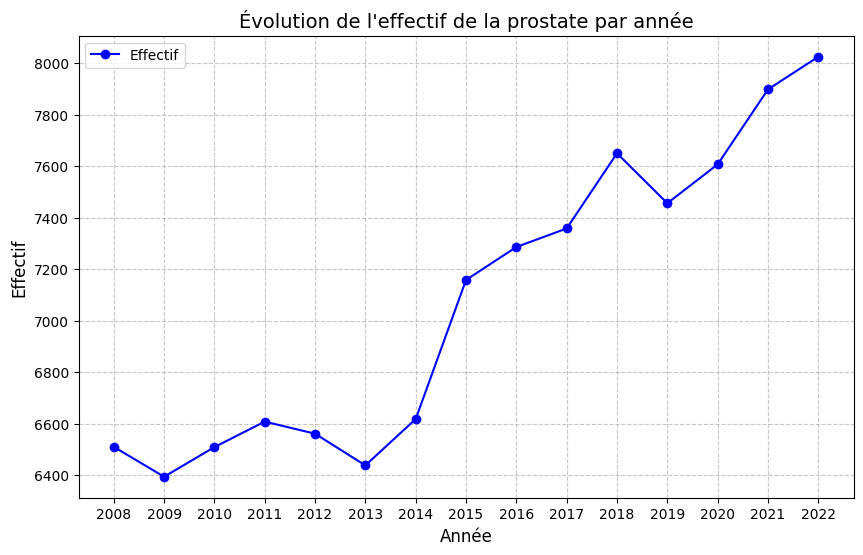

In [13]:
plt.figure(figsize=(10, 6))  # Taille de la figure
plt.plot(df_total["année"], df_total["Effectif"],
         marker='o',  # Ajoute des marqueurs pour chaque point
         linestyle='-',  # Ligne continue
         color='blue',  # Couleur de la ligne
         label="Effectif")

# Personnalisation du graphique
plt.title("Évolution de l'effectif de la prostate par année", fontsize=14)
plt.xlabel("Année", fontsize=12)
plt.ylabel("Effectif", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)  # Grille discrète
plt.xticks(df_total["année"])  # Affiche toutes les années sur l'axe X
plt.legend()

# Affiche le graphique
plt.show()